## 2D vs 3D plane fitting to GB

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
import pandas as pd

### Read normal vectors to basal plane for the grains of interest (c-axis):
#### 1- In Paraview, click in the corresponding grain and read voxel info "normal_vector_to_basal_plane" 
#### 2- Insert below the result with the format [Y, -Z, X]

In [54]:
# c-axis vectors of grains forming OR with hydrides, obtained from dream3d pipeline:
caxis_OR_vector= {
    'Hydride 1-p1': [-0.535, -0.864, 0.243],
    'Hydride 1-p2': [-0.535, -0.864, 0.243],
    'Hydride 2-p1': [-0.074, -0.630, -0.773],
    'Hydride 2-p2': [-0.074, -0.630, -0.773],
    'Hydride 3': [-0.257, 0.515, -0.129],
    'Hydride 4-p1':[-0.257, 0.515, -0.129],
    'Hydride 4-p2':[-0.257, 0.515, -0.129],
    'Hydride 5-p1':[-0.278, -0.555, -0.278],
    'Hydride 5-p2':[-0.278, -0.555, -0.278],
    'Hydride 6':[-0.281, 0.952, -0.073],
    'Hydride 7':[-0.358, 0.963, 0.178],
    'Hydride 8':[-0.005, -0.251, -0.997],
    'Hydride 9':[-0.206, 0.337, 0.963],
}

caxis_OR_vector_large = {    
    'Hydride 11':[-0.482, -0.863, -0.154],
    'Hydride 13':[-0.276, -0.863, -0.423],
    'Hydride 14':[-0.038, -0.690, 0.723],
    'Hydride 15':[-0.038, -0.690, 0.723],
    'Hydride 16-p1':[-0.221, -0.905, -0.363],    
    'Hydride 16-p2':[-0.221, -0.905, -0.363],
    'Hydride 17': [-0.106, -0.798, 0.594],
    'Hydride 18' : [-0.487, -0.595, -0.639]
}

### Do the plane fitting in Paraview and insert the vector of that plane here:

In [55]:
# 2D plane fitting: Vectors perpendicular to the planes fitted to GB, measured in Paraview
normal_vector2D= {
    'Hydride 1-p1': [0.950, 0.175, 0.258],
    'Hydride 1-p2': [0.984, 0.016, 0.176],
    'Hydride 2-p1': [-0.661, -0.113, 0.741],
    'Hydride 2-p2': [-0.526, -0.496, 0.691],
    'Hydride 3':[0.456, -0.872, 0.182],
    'Hydride 4-p1':[0.679, 0.732, -0.057],
    'Hydride 4-p2':[0.380, 0.899, -0.219],
    'Hydride 5-p1':[0.249, -0.954, -0.169],
    'Hydride 5-p2':[0.178, -0.961, -0.212],
    'Hydride 6':[-0.365,0.037,0.930],
    'Hydride 7':[-0.019, 0.118, 0.993],
    'Hydride 8':[0.706, 0.113, 0.699],
    'Hydride 9':[0.411, 0.165, 0.897 ]
}

normal_vector2D_large= {
    'Hydride 11' : [0.084, 0.707, 0.702],
    'Hydride 13' : [-0.842, -0.015, 0.540],
    'Hydride 14' : [-0.172, 0.949, 0.264],
    'Hydride 15' : [-0.641, 0.231, 0.731],
    'Hydride 16-p1' : [0.434, -0.745, -0.507],
    'Hydride 16-p2' : [-0.322, 0.907, 0.271],
    'Hydride 17': [-0.002, 0.981, 0.194],
    'Hydride 18' : [-0.198, 0.948, 0.250]
}

In [56]:
# 3D plane fitting: Vectors perpendicular to the planes fitted to GB, measured in Paraview
normal_vector3D= {
    'Hydride 1-p1': [0.950, 0.175, 0.258],
    'Hydride 1-p2': [0.984, 0.016, 0.176],
    'Hydride 2-p1': [-0.661, -0.113, 0.741],
    'Hydride 2-p2': [-0.526, -0.496, 0.691],
    'Hydride 3':[0.456, -0.872, 0.182],
    'Hydride 4-p1':[0.679, 0.732, -0.057],
    'Hydride 4-p2':[0.380, 0.899, -0.219],
    'Hydride 5-p1':[0.249, -0.954, -0.169],
    'Hydride 5-p2':[0.178, -0.961, -0.212],
    'Hydride 6':[-0.365,0.037,0.930],
    'Hydride 7':[-0.019, 0.118, 0.993],
    'Hydride 8':[0.706, 0.113, 0.699],
    'Hydride 9':[0.411, 0.165, 0.897 ]
}
normal_vector3D_large= {    
    'Hydride 11' : [0.084, 0.707, 0.702],
    'Hydride 13' : [-0.842, -0.015, 0.540],
    'Hydride 14' : [-0.172, 0.949, 0.264],
    'Hydride 15' : [-0.641, 0.231, 0.731],
    'Hydride 16-p1' : [0.434, -0.745, -0.507],
    'Hydride 16-p2' : [-0.322, 0.907, 0.271],
    'Hydride 17': [-0.002, 0.981, 0.194],
    'Hydride 18' : [-0.198, 0.948, 0.250]
}

### Calculate the angle between the two vectors:


In [57]:
# Function to calculate the angle between two vectors:

def angle(n, b): # θ=arctan2(∥n×b∥,|n⋅b|)
    dot = np.dot(n, b)
    normcross = np.linalg.norm(np.cross(n, b))
    dot = abs(dot)  # make angle insensitive to sign flips
    # Use atan2 for better numerical stability than arccos
    return np.degrees(np.arctan2(normcross, dot))

In [60]:
# Calculate angle between c-axis vector and normal vector to GBs from 2D and 3D plane fitting:

angles_OR2D = {}
angles_OR3D = {}
angles_OR2D_large = {}
angles_OR3D_large = {}


for h in caxis_OR_vector:
    angles_OR2D[h] = int(np.round(angle(caxis_OR_vector[h], normal_vector2D[h])))
    angles_OR3D[h] = int(np.round(angle(caxis_OR_vector[h], normal_vector3D[h])))
    angles_OR2D_large[h] = int(np.round(angle(caxis_OR_vector_large[h], normal_vector2D_large[h])))
    angles_OR3D_large[h] = int(np.round(angle(caxis_OR_vector_large[h], normal_vector3D_large[h])))

labels = list(angles_OR2D.keys())
labels_large = list(angles_OR2D_large.keys())
values2D = list(angles_OR2D.values())
values3D = list(angles_OR3D.values())
values2D_large = list(angles_OR2D_large.values())
values3D_large = list(angles_OR3D_large.values())

KeyError: 'Hydride 1-p1'

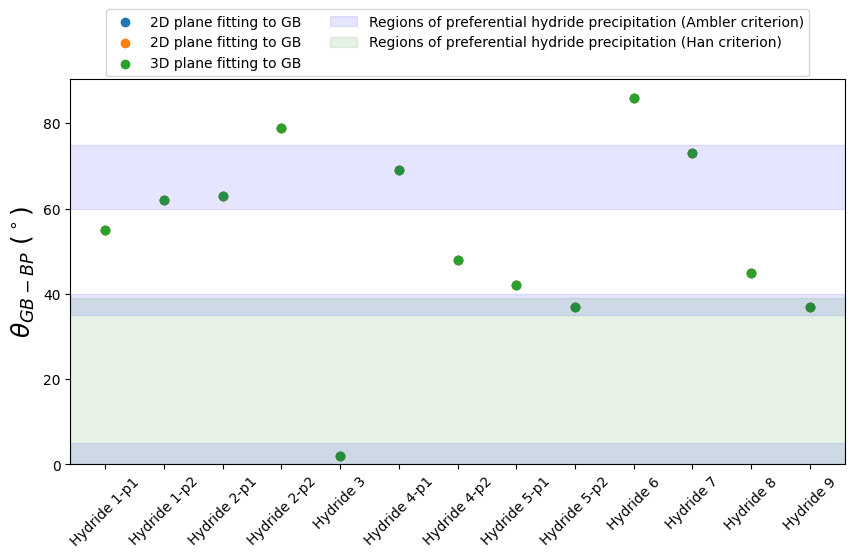

In [61]:
# Plotting the angles and comparing 2D vs 3D plane fitting for three hydrides:
plt.figure(figsize=(10, 5))

plt.scatter(labels, values2D, label="2D plane fitting to GB")
plt.scatter(labels, values2D, label="2D plane fitting to GB")
plt.scatter(labels, values3D, label="3D plane fitting to GB")


# Ambler critetion:
plt.axhspan(60, 75, color='blue', alpha=0.1, label='Regions of preferential hydride precipitation (Ambler criterion)')
plt.axhspan(35, 40, color='blue', alpha=0.1)
plt.axhspan(0, 5, color='blue', alpha=0.1)

# Han criterion:
plt.axhspan(0, 39, color='green', alpha=0.1, label='Regions of preferential hydride precipitation (Han criterion)')

plt.ylabel(r'$\theta_{GB-BP}\ (^\circ)$', fontsize=18)

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2), ncol=2)
#plt.margins(x=0.1)

plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.show()